# 08. 최종 후보 seed 반복 비교와 모델 선정

E05~E07에서 바벨·덤벨 묶음(2·7·9)의 경계가 불안정해, 단일 실행의 0.01~0.02 차이로는 후보를 가를 수 없었습니다. 그래서 후보마다 **seed 3개(42·43·44)** 로 반복합니다. seed가 바꾸는 것은 새 `fc` 초기값, Train 순서, 증강의 무작위성입니다.

| 후보 | 조건 | 실행(seed 42 / 43 / 44) |
|---|---|---|
| A. Full 기본 | 입력 224, 증강 없음 | E04 / SEL-A-s43 / SEL-A-s44 |
| B. Full + 증강 | 입력 224, 증강 basic | E05d / SEL-B-s43 / SEL-B-s44 |
| C. Full 384 | 입력 384, 증강 없음 | E07a / SEL-C-s43 / SEL-C-s44 |

**선정 규칙(실행 전에 `experiments/SEL/PLAN.md`와 D-030에 적음)**
1. 3회 중 2회 이상에서 어떤 클래스든 Val Recall < 0.20이면 제외(클래스 붕괴)
2. 남은 후보 중 Val Macro F1 **3회 평균** 최고
3. 1·2위 평균 차이 < 두 후보 표준편차 중 큰 값 → 구분 불가 → 입력 224 우선, 그다음 증강 없음 우선
4. Test에는 고른 후보의 **중앙값 seed** 가중치(가장 좋은 seed를 고르면 Val에 맞춘 낙관이 섞임)
5. 선정을 기록한 뒤 Test 1회. Test를 보고 바꾸지 않음

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import FIGURES, GROUPS, class_names, set_korean_font

print("font:", set_korean_font())
pd.set_option("display.width", 200)
NAMES = class_names()
CANDS = {"A. Full 기본": ["E04", "SEL-A-s43", "SEL-A-s44"],
         "B. Full + 증강": ["E05d", "SEL-B-s43", "SEL-B-s44"],
         "C. Full 384": ["E07a", "SEL-C-s43", "SEL-C-s44"]}
COST = {"A. Full 기본": (224, 0), "B. Full + 증강": (224, 1), "C. Full 384": (384, 0)}  # 구분 불가일 때 우선순위(작을수록 우선)
rows = []
for cand, rids in CANDS.items():
    for seed, rid in zip((42, 43, 44), rids):
        sm = json.loads((ROOT / "experiments" / rid / "full" / "summary.json").read_text(encoding="utf-8"))
        cfg = json.loads((ROOT / "experiments" / rid / "full" / "config.json").read_text(encoding="utf-8"))
        assert cfg["seed"] == seed, (rid, cfg["seed"])
        rec = sm["val"]["per_class"]["recall"]
        worst = min(rec, key=rec.get)
        rows.append({"후보": cand, "seed": seed, "실행": rid, "Val Macro F1": sm["val"]["macro_f1"], "Val Acc": sm["val"]["accuracy"],
                     "최저 Recall": rec[worst], "최저 클래스": worst, "바벨 로우": rec["바벨 로우"], "데드리프트": rec["바벨 데드리프트"],
                     "덤벨 로우": rec["덤벨 벤트오버 로우"], "최고 epoch": sm["best_epoch"], "시간(분)": sm["total_time_s"] / 60})
runs = pd.DataFrame(rows)
runs.round(3)

font: Malgun Gothic


,후보,seed,실행,Val Macro F1,Val Acc,최저 Recall,최저 클래스,바벨 로우,데드리프트,덤벨 로우,최고 epoch,시간(분)
0,A. Full 기본,42,E04,0.858,0.866,0.400,바벨 데드리프트,0.531,0.400,0.794,16,4.385
1,A. Full 기본,43,SEL-A-s43,0.878,0.887,0.484,바벨 로우,0.484,0.594,0.775,8,2.837
2,A. Full 기본,44,SEL-A-s44,0.884,0.897,0.531,바벨 로우,0.531,0.544,0.912,7,2.596
3,B. Full + 증강,42,E05d,0.870,0.875,0.578,바벨 로우,0.578,0.594,0.662,8,2.806
4,B. Full + 증강,43,SEL-B-s43,0.864,0.875,0.469,바벨 로우,0.469,0.756,0.506,5,2.248
5,B. Full + 증강,44,SEL-B-s44,0.866,0.894,0.188,바벨 로우,0.188,0.725,0.825,14,3.862
6,C. Full 384,42,E07a,0.873,0.919,0.031,바벨 로우,0.031,0.850,0.969,4,4.330
7,C. Full 384,43,SEL-C-s43,0.885,0.915,0.219,바벨 로우,0.219,0.812,0.912,11,7.413
8,C. Full 384,44,SEL-C-s44,0.882,0.912,0.156,바벨 로우,0.156,0.738,0.919,16,9.591


## 1. 규칙 적용

In [2]:
agg = runs.groupby("후보").agg(F1_평균=("Val Macro F1", "mean"), F1_표준편차=("Val Macro F1", "std"),
                               F1_최소=("Val Macro F1", "min"), F1_최대=("Val Macro F1", "max"),
                               Acc_평균=("Val Acc", "mean"),
                               붕괴_횟수=("최저 Recall", lambda x: int((x < 0.20).sum())),
                               바벨로우_평균=("바벨 로우", "mean"), 시간_평균=("시간(분)", "mean"))
agg["제외(규칙 1)"] = agg["붕괴_횟수"] >= 2
display(agg.round(4))

alive = agg[~agg["제외(규칙 1)"]].sort_values("F1_평균", ascending=False)
print("규칙 1로 제외:", agg.index[agg["제외(규칙 1)"]].tolist() or "없음")
if len(alive) == 0:
    raise RuntimeError("모든 후보가 제외됨: 규칙을 다시 정해야 함(사용자 판단)")
first = alive.index[0]
chosen, reason = first, "3회 평균 Macro F1 최고"
if len(alive) > 1:
    second = alive.index[1]
    gap = alive.loc[first, "F1_평균"] - alive.loc[second, "F1_평균"]
    thr = max(alive.loc[first, "F1_표준편차"], alive.loc[second, "F1_표준편차"])
    print(f"1위 {first} vs 2위 {second}: 평균 차이 {gap:.4f}, 기준(큰 표준편차) {thr:.4f}")
    if gap < thr:
        chosen = min((first, second), key=lambda c: COST[c])
        reason = f"구분 불가(차이 {gap:.4f} < {thr:.4f}) → 비용·단순성 우선(규칙 3)"
pick = runs[runs["후보"] == chosen].sort_values("Val Macro F1").iloc[1]  # 중앙값 seed(규칙 4)
print(f"\n선정 후보: {chosen} ({reason})")
print(f"Test에 쓸 가중치: {pick['실행']} (seed {pick['seed']}, Val Macro F1 {pick['Val Macro F1']:.4f}, 후보 내 중앙값)")

,F1_평균,F1_표준편차,F1_최소,F1_최대,Acc_평균,붕괴_횟수,바벨로우_평균,시간_평균,제외(규칙 1)
후보,,,,,,,,,
A. Full 기본,0.8736,0.0138,0.8581,0.8845,0.8831,0,0.5156,3.2725,False
B. Full + 증강,0.8666,0.0029,0.8640,0.8698,0.8812,1,0.4115,2.9720,False
C. Full 384,0.8800,0.0059,0.8734,0.8847,0.9150,2,0.1354,7.1118,True


규칙 1로 제외: ['C. Full 384']
1위 A. Full 기본 vs 2위 B. Full + 증강: 평균 차이 0.0070, 기준(큰 표준편차) 0.0138

선정 후보: A. Full 기본 (구분 불가(차이 0.0070 < 0.0138) → 비용·단순성 우선(규칙 3))
Test에 쓸 가중치: SEL-A-s43 (seed 43, Val Macro F1 0.8782, 후보 내 중앙값)


## 2. seed별 흔들림 보기

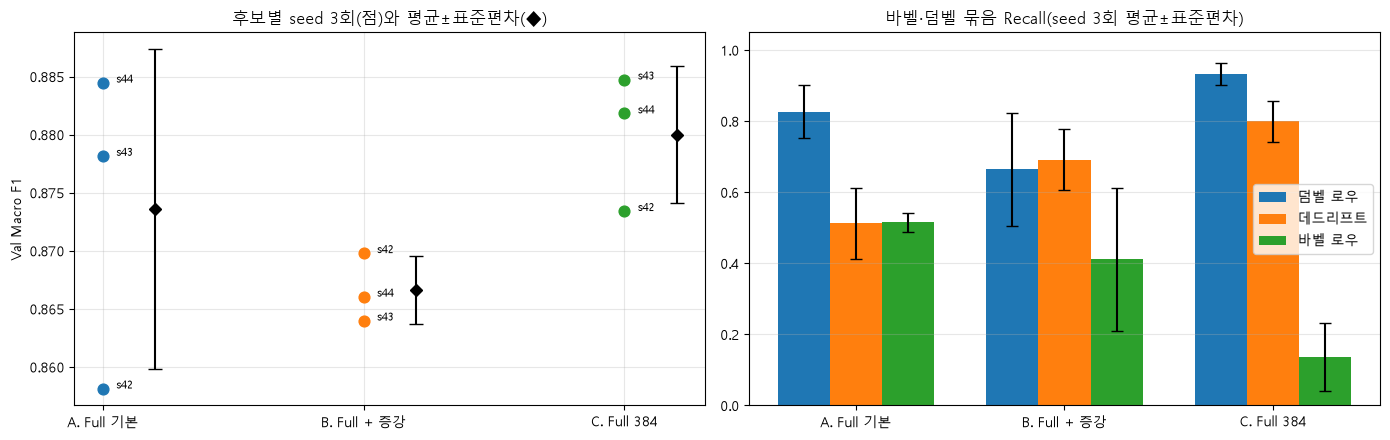

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for i, (cand, g) in enumerate(runs.groupby("후보", sort=False)):
    axes[0].scatter([i] * len(g), g["Val Macro F1"], s=60, zorder=3)
    for _, r in g.iterrows(): axes[0].annotate(f"s{r.seed}", (i + 0.05, r["Val Macro F1"]), fontsize=8)
    axes[0].errorbar(i + 0.2, g["Val Macro F1"].mean(), yerr=g["Val Macro F1"].std(), fmt="D", color="k", capsize=5)
axes[0].set_xticks(range(len(CANDS))); axes[0].set_xticklabels(CANDS.keys()); axes[0].set_ylabel("Val Macro F1")
axes[0].set_title("후보별 seed 3회(점)와 평균±표준편차(◆)"); axes[0].grid(alpha=.3)
x = np.arange(3); wdt = 0.25
for k, cls in enumerate(("덤벨 로우", "데드리프트", "바벨 로우")):
    m = runs.groupby("후보", sort=False)[cls].mean(); s = runs.groupby("후보", sort=False)[cls].std()
    axes[1].bar(x + (k - 1) * wdt, m.values, wdt, yerr=s.values, capsize=4, label=cls)
axes[1].set_xticks(x); axes[1].set_xticklabels(CANDS.keys()); axes[1].set_ylim(0, 1.05); axes[1].legend()
axes[1].set_title("바벨·덤벨 묶음 Recall(seed 3회 평균±표준편차)"); axes[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(FIGURES / "sel_seed_compare.png", dpi=110); plt.show()

In [4]:
order = [c for g in GROUPS.values() for c in g]
tab = {}
for cand, rids in CANDS.items():
    recs = np.array([[json.loads((ROOT / "experiments" / r / "full" / "summary.json").read_text(encoding="utf-8"))["val"]["per_class"]["recall"][NAMES[c]]
                      for c in order] for r in rids])
    tab[cand] = [f"{m:.2f}±{s:.2f}" for m, s in zip(recs.mean(0), recs.std(0, ddof=1))]
print("클래스별 Val Recall(seed 3회 평균±표준편차)")
pd.DataFrame(tab, index=[f"{c} {NAMES[c]}" for c in order])

클래스별 Val Recall(seed 3회 평균±표준편차)


,A. Full 기본,B. Full + 증강,C. Full 384
0 Y - Exercise,0.97±0.00,0.93±0.04,0.99±0.01
1 니푸쉬업,1.00±0.00,1.00±0.00,1.00±0.00
4 라잉 레그 레이즈,0.91±0.05,0.93±0.03,0.90±0.07
10 바이시클 크런치,0.93±0.04,0.94±0.05,0.93±0.05
2 덤벨 벤트오버 로우,0.83±0.07,0.66±0.16,0.93±0.03
7 바벨 데드리프트,0.51±0.10,0.69±0.09,0.80±0.06
8 바벨 런지,0.94±0.01,0.97±0.02,0.97±0.02
9 바벨 로우,0.52±0.03,0.41±0.20,0.14±0.10
3 딥스,1.00±0.00,1.00±0.00,1.00±0.00
5 랫풀 다운,0.98±0.00,0.98±0.00,0.98±0.00


## 3. 해석

### 3.1 선정 결과

| 후보 | Val Macro F1(평균 ± 표준편차) | 범위 | 바벨 로우 Recall 평균 | Recall < 0.20 | 판정 |
|---|---|---|---|---|---|
| A. Full 기본 | **0.874 ± 0.014** | 0.858~0.884 | 0.52 | 0회 | **선정** |
| B. Full + 증강 | 0.867 ± 0.003 | 0.864~0.870 | 0.41 | 1회 | A와 구분 불가 |
| C. Full 384 | 0.880 ± 0.006 | 0.873~0.885 | 0.14 | 2회 | 제외(규칙 1) |

- **선정 모델: 후보 A(Full FT, 입력 224, 증강 없음).** Test에는 중앙값 seed인 `SEL-A-s43`(seed 43, Val Macro F1 0.878) 가중치를 씁니다. 저장한 가중치로 다시 예측해도 0.878이 나와 일치합니다.
- **C는 평균이 가장 높았지만 제외했습니다.** Accuracy도 0.915로 가장 높았습니다. 그러나 seed 3번 중 2번 바벨 로우를 거의 맞히지 못했습니다(0.03, 0.16). Macro F1 평균이 높아도 한 운동을 체계적으로 놓치는 모델은 "12개 운동을 고르게 맞힌다"는 목표에 맞지 않습니다. 이 기준은 결과를 보기 전에 정했습니다.
- **A와 B는 구분할 수 없습니다.** 평균 차이(0.007)가 A의 흔들림(표준편차 0.014)보다 작습니다. 그래서 더 단순한 A를 골랐습니다. B는 seed마다 덤벨 로우(0.66 ± 0.16)와 바벨 로우(0.41 ± 0.20)가 크게 흔들렸습니다.

### 3.2 seed 반복으로 배운 것

- **seed만 바꿔도 같은 조건의 점수가 0.858~0.884로 0.026 움직였습니다**(후보 A). 앞에서 "차이 없음"의 기준을 ±0.02로 둔 것이 과하지 않았습니다.
- 기본 실행 E04(seed 42, 0.858)는 A의 세 번 중 **가장 나쁜 실행**이었습니다. 그래서 E05d(증강, 0.870)·E07a(384, 0.873)가 "+0.012~0.015 좋아 보였던 것"의 상당 부분은 seed 운의 차이로 설명됩니다. seed 하나로 결론을 냈다면 증강이나 384를 "개선"으로 잘못 읽었을 수 있습니다.
- 반대로 **C(384)가 바벨 로우를 놓치는 경향은 seed가 바뀌어도 유지되었습니다**(0.03, 0.22, 0.16). 해상도 384가 데드리프트를 잘 맞히는 대신 바벨 로우를 희생시키는 것은 운이 아니라 구조적인 경향으로 보입니다.
- 클래스별로 보면, seed가 바뀌어도 거의 그대로인 클래스(기구 묶음, 니푸쉬업 등)와 크게 흔들리는 클래스(2·7·9)가 뚜렷이 나뉩니다. Macro F1의 흔들림은 대부분 이 세 클래스에서 나옵니다.

### 3.3 Test 전에 확인할 것

- 선정과 사용할 가중치를 `docs/decision_log.md`에 적은 뒤 Test를 **한 번만** 평가합니다. Test 결과를 보고 후보나 가중치를 바꾸지 않습니다(O-05, D-030 규칙 5).
- Test도 운동마다 한 사람(3명)이므로, Val과 다른 사람에 대한 결과입니다. Val의 클래스별 약점(2·7·9)이 Test에서도 나타나는지가 일반화의 핵심 확인 지점입니다.